# Think-or-Stop: Model Building and Training Walkthrough (PyTorch)

This notebook explains, step by step, how the **Think-or-Stop adaptive early-exit CNN** is built, trained and
tested. It does **not** re-implement the project: it **imports the real functions** from `src/think_or_stop/*.py`
and shows their actual source code, so everything here is exactly what produced the reported results.

| Step | Section | Project file |
|---|---|---|
| 1 | Imports | – |
| 2 | Configuration (hyper-parameters) | `config.py` |
| 3 | Dataset loading | `datasets.py` |
| 4 | Preprocessing (normalisation, augmentation, mini-batches) | `datasets.py` |
| 5 | CNN architecture: 3 stages + 3 exit classifiers | `models.py` |
| 6 | Loss function: weighted multi-exit cross-entropy | `losses.py` |
| 7 | Optimizer and learning-rate schedule | `train.py` |
| 8 | Training: forward pass → loss → backpropagation → update → validation → checkpoint | `train.py` |
| 9 | Evaluation: testing the trained model | `evaluate.py`, `inference.py`, `metrics.py` |

**How to run:** open this notebook with the project's `.venv` Python kernel and run the cells from top to bottom.

**Safety:** nothing is trained and no checkpoint is written unless you set `RUN_FULL_TRAINING = True` in
Section 8.5. Sections 8.4 and 9 only **read** the saved checkpoint `checkpoints/cifar10_multiexit_s0/best.pt`.
CIFAR-10 must already be downloaded into `data/raw` (`python -m think_or_stop.download --dataset cifar10`).

## 1. Imports

* **`torch`** – tensors (multi-dimensional arrays on CPU/GPU) and *autograd*, which computes gradients for
  backpropagation automatically.
* **`torch.nn.functional`** – functions such as `softmax` and `cross_entropy`.
* **`numpy`, `matplotlib`** – numbers and plots.
* **Project modules** – our own code in `src/think_or_stop/`. We import them instead of copying them, so the notebook
  can never drift away from the real implementation.

In [2]:
# --- Locate the project folder so relative paths (data/raw, checkpoints/) work ----------------
import os, sys, inspect, json, csv, copy, math
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src" / "think_or_stop").exists() else Path.cwd().parent
os.chdir(ROOT)                                  # every project path is relative to the project root
if str(ROOT / "src") not in sys.path:           # works even if the package is not pip-installed
    sys.path.insert(0, str(ROOT / "src"))

# --- Third-party libraries ----------------------------------------------------------------------
import numpy as np
import torch                                    # tensors + autograd (automatic gradients)
import torch.nn.functional as F                 # softmax, cross_entropy
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Code, display       # used to show the project's real source code

# --- Our project code (src/think_or_stop/*.py) ---------------------------------------------------
from think_or_stop.config import TrainConfig                       # all hyper-parameters in one place
from think_or_stop.datasets import build_splits, build_transforms, make_loader, split_indices
from think_or_stop.models import (build_model, make_stage, make_head, ThinkOrStopCNN,
                                  compute_exit_costs, count_parameters)
from think_or_stop.losses import MultiExitLoss, build_loss
from think_or_stop.train import build_optimizer, build_scheduler, train_one_epoch, validate, run
from think_or_stop.inference import adaptive_predict
from think_or_stop.evaluate import load_model, collect_probs
from think_or_stop.metrics import adaptive_summary
from think_or_stop.utils import set_seed, load_checkpoint


def show_source(obj):
    """Display the real source code of a project function or class (nothing is re-typed by hand)."""
    display(Code(inspect.getsource(obj), language="python"))


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EXIT_COLORS = ["#2A55A1", "#C2570C", "#518113"]   # Exit 1 blue, Exit 2 orange, Exit 3 green

print("Project root :", ROOT)
print("Python       :", sys.executable)
print("PyTorch      :", torch.__version__, "| CUDA build:", torch.version.cuda)
print("Device       :", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")

Project root : g:\Projects\ThinkOrStop
Python       : g:\Projects\ThinkOrStop\.venv\Scripts\python.exe
PyTorch      : 2.14.1+cu130 | CUDA build: 13.0
Device       : cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


## 2. Configuration (hyper-parameters)

All settings live in one dataclass, `TrainConfig` (`config.py`); the command line and `run_all.ps1` fill the same
object. The values below are the ones used for the reported CIFAR-10 multi-exit run with seed 0.
The last lines check them against the `config.json` that the real training run saved, so we know the
notebook describes the actual experiment.

In [3]:
cfg = TrainConfig(
    dataset="cifar10",              # main benchmark (MNIST was only used as a quick smoke test)
    model="multiexit",              # 3 stages + 3 exit classifiers ("baseline" = final exit only)
    epochs=30,                      # 30 full passes over the 45,000 training images
    batch_size=128,                 # images per mini-batch
    optimizer="adam",
    lr=1e-3,                        # Adam learning rate
    weight_decay=1e-4,              # mild L2 regularisation against overfitting
    scheduler="cosine",             # learning rate decays smoothly to 0 over the 30 epochs
    exit_weights=(1.0, 1.0, 1.0),   # loss weights w1, w2, w3 of the three exits
    base_channels=64,               # Stage 1 width; Stage 2 = 128, Stage 3 = 256 channels
    dropout=0.3,                    # dropout inside each exit head
    seed=0,                         # randomness of weights, shuffling and augmentation
    split_seed=42,                  # fixed train/validation split (same for every seed)
    device=str(DEVICE),
)
for k in ["dataset", "model", "epochs", "batch_size", "optimizer", "lr", "weight_decay", "scheduler",
          "exit_weights", "base_channels", "dropout", "seed", "split_seed", "select_metric"]:
    print(f"{k:>14} : {getattr(cfg, k)}")

# Check: are these exactly the settings the saved training run used?
saved_cfg_path = ROOT / "results/logs/cifar10_multiexit_s0/config.json"
if saved_cfg_path.exists():
    saved = json.loads(saved_cfg_path.read_text())["config"]
    ignore = {"device", "num_workers", "run_name", "output_dir", "data_dir", "download", "resume", "max_train_batches"}
    diff = {k: (v, getattr(cfg, k)) for k, v in saved.items()
            if k not in ignore and (tuple(v) if isinstance(v, list) else v) != getattr(cfg, k)}
    print("\nSame as the saved run's config.json:", "YES" if not diff else f"NO -> {diff}")
else:
    print("\n(No saved run found to compare with.)")

       dataset : cifar10
         model : multiexit
        epochs : 30
    batch_size : 128
     optimizer : adam
            lr : 0.001
  weight_decay : 0.0001
     scheduler : cosine
  exit_weights : (1.0, 1.0, 1.0)
 base_channels : 64
       dropout : 0.3
          seed : 0
    split_seed : 42
 select_metric : final_acc

Same as the saved run's config.json: YES


## 3. Dataset loading

**CIFAR-10**: 60,000 colour images of 32×32 pixels in 10 classes – 50,000 official training images and 10,000
official test images.

We split the official training set once more, because we need data for **decisions** that the test set must
never influence:

| Split | Images | Used for |
|---|---|---|
| Training | 45,000 | learning the weights (gradient descent) |
| Validation | 5,000 | choosing the best epoch and, later, the exit threshold τ |
| Test | 10,000 | final evaluation only – never for training or tuning |

The 5,000 validation images are chosen by a random permutation with a **fixed seed (42)**, so every run uses
exactly the same split. This is the real function:

In [4]:
show_source(split_indices)

def split_indices(n: int, val_size: int, seed: int) -> tuple[np.ndarray, np.ndarray]:
    """Deterministically split ``range(n)`` into disjoint train/val index arrays."""
    if not 0 < val_size < n:
        raise ValueError(f"val_size must be in (0, {n}), got {val_size}")
    gen = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=gen).numpy()
    val_idx = np.sort(perm[:val_size])
    train_idx = np.sort(perm[val_size:])
    return train_idx, val_idx

In [5]:
# build_splits() returns the three datasets with the correct transforms already attached.
# download=False: the data must already be in data/raw (no hidden internet access).
splits = build_splits(cfg.dataset, cfg.data_dir, cfg.split_seed, download=False)
spec = cfg.spec                       # dataset facts: channels, image size, class names, mean/std

print(f"Training   : {len(splits.train):>6} images")
print(f"Validation : {len(splits.val):>6} images")
print(f"Test       : {len(splits.test):>6} images")
print("Classes    :", ", ".join(spec.classes))
print("Images in both training and validation:", len(set(splits.train_indices) & set(splits.val_indices)),
      "(must be 0)")

Training   :  45000 images
Validation :   5000 images
Test       :  10000 images
Classes    : airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
Images in both training and validation: 0 (must be 0)


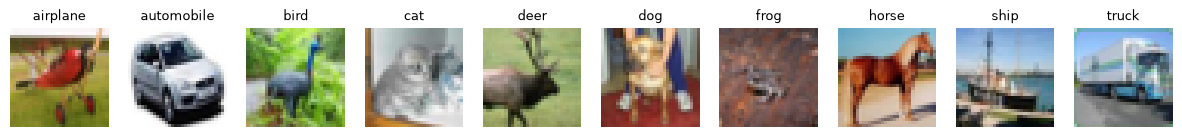

In [6]:
# One validation image per class. Stored images are normalised, so we undo that only for display.
MEAN = torch.tensor(spec.mean).view(3, 1, 1)
STD = torch.tensor(spec.std).view(3, 1, 1)

def to_image(x):
    """Normalised tensor (3, 32, 32) -> displayable array (32, 32, 3) with values in [0, 1]."""
    return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

found = {}
for i in range(len(splits.val)):
    x, y = splits.val[i]
    found.setdefault(y, x)
    if len(found) == 10:
        break
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c, ax in enumerate(axes):
    ax.imshow(to_image(found[c])); ax.set_title(spec.classes[c], fontsize=9); ax.axis("off")
plt.show()

## 4. Preprocessing

1. **`ToTensor`** – converts a picture (32×32×3, values 0–255) into a float tensor of shape **3×32×32**
   (channels × height × width) with values 0–1.
2. **`Normalize`** – computes `(x − mean) / std` for each colour channel, so inputs are centred around 0 with
   similar scales. This makes gradient descent faster and more stable.
3. **Data augmentation (training images only)** – `RandomCrop(32, padding=4)` shifts the image a little and
   `RandomHorizontalFlip` mirrors it with probability 0.5. Every epoch the network sees slightly different
   versions of each image, which **reduces overfitting**. Validation and test images are *not* augmented, so
   evaluation is deterministic.
4. **`DataLoader`** – groups images into **mini-batches** of 128 and shuffles the training set every epoch.

In [7]:
train_tf = build_transforms(spec, augment=True)     # attached to the training split
eval_tf = build_transforms(spec, augment=False)     # attached to the validation and test splits
print("Training transform:\n", train_tf)
print("\nEvaluation transform:\n", eval_tf)

Training transform:
 Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Evaluation transform:
 Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


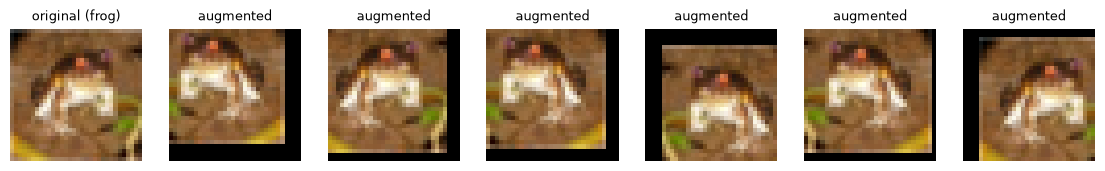

Raw picture    : (32, 32, 3) uint8, values 0 to 255
After transform: (3, 32, 32) float32; per-channel mean [ 0.25 -0.29 -0.75] std [0.65 0.68 0.61]


In [8]:
# Apply the TRAINING transform several times to the SAME raw image:
# every call gives a different random crop/flip, so the network rarely sees the exact same picture twice.
idx = splits.train.indices[0]
raw = Image.fromarray(splits.train.dataset.data[idx])          # original 32x32 RGB picture, values 0..255
label = spec.classes[splits.train.dataset.targets[idx]]

torch.manual_seed(0)
fig, axes = plt.subplots(1, 7, figsize=(14, 2.3))
axes[0].imshow(raw); axes[0].set_title(f"original ({label})", fontsize=9)
for ax in axes[1:]:
    ax.imshow(to_image(train_tf(raw))); ax.set_title("augmented", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

x = eval_tf(raw)
print("Raw picture    :", np.array(raw).shape, "uint8, values", np.array(raw).min(), "to", np.array(raw).max())
print("After transform:", tuple(x.shape), "float32; per-channel mean", x.mean(dim=(1, 2)).numpy().round(2),
      "std", x.std(dim=(1, 2)).numpy().round(2))

In [9]:
# Mini-batches. num_workers=0 keeps this demo simple; real training uses parallel loader processes.
train_loader = make_loader(splits.train, cfg.batch_size, shuffle=True, num_workers=0, device=DEVICE, seed=cfg.seed)
val_loader = make_loader(splits.val, cfg.batch_size, shuffle=False, num_workers=0, device=DEVICE)

xb, yb = next(iter(train_loader))
print("One training batch :", tuple(xb.shape), "-> (batch, channels, height, width)")
print("Its labels         :", tuple(yb.shape), "first 10 =", yb[:10].tolist())
print("Batches per epoch  :", len(train_loader), "training,", len(val_loader), "validation")

One training batch : (128, 3, 32, 32) -> (batch, channels, height, width)
Its labels         : (128,) first 10 = [1, 3, 7, 6, 7, 6, 7, 0, 8, 8]
Batches per epoch  : 352 training, 40 validation


## 5. CNN architecture: 3 stages and 3 exit classifiers

```
input image 3×32×32
  → Stage 1: [Conv 3×3 (64)  → BatchNorm → ReLU] ×2 → MaxPool 2×2  →  64×16×16  → Exit 1 head → 10 scores
  → Stage 2: [Conv 3×3 (128) → BatchNorm → ReLU] ×2 → MaxPool 2×2  → 128×8×8   → Exit 2 head → 10 scores
  → Stage 3: [Conv 3×3 (256) → BatchNorm → ReLU] ×2 → MaxPool 2×2  → 256×4×4   → Exit 3 head → 10 scores (final)
```

* **Convolution (3×3, padding 1)** learns small filters that detect patterns; padding keeps width and height.
* **Batch normalisation** keeps each layer's outputs in a stable range → faster, steadier training.
* **ReLU** `max(0, x)` adds non-linearity.
* **Max pooling 2×2** halves width and height. Channels double at each stage while the image gets smaller:
  early stages see fine detail, later stages see more abstract features.
* **Exit head** (classifier): AdaptiveAvgPool(2×2) → Flatten → Fully connected → ReLU → **Dropout(0.3)** →
  Fully connected → 10 class scores (*logits*).
* The **standard CNN baseline** has the same three stages and the same final head, but **no Exit 1 or Exit 2**,
  so the two models differ only in the extra classifiers.

The real building blocks:

In [10]:
show_source(make_stage)    # one stage = two Conv-BN-ReLU blocks + max pooling
show_source(make_head)     # one exit classifier

def make_stage(in_ch: int, out_ch: int) -> nn.Sequential:
    return nn.Sequential(conv_block(in_ch, out_ch), conv_block(out_ch, out_ch), nn.MaxPool2d(2))

def make_head(in_ch: int, num_classes: int, dropout: float) -> nn.Sequential:
    return nn.Sequential(
        nn.AdaptiveAvgPool2d(HEAD_POOL),
        nn.Flatten(),
        nn.Linear(in_ch * HEAD_POOL * HEAD_POOL, HEAD_HIDDEN),
        nn.ReLU(inplace=True),
        nn.Dropout(dropout),
        nn.Linear(HEAD_HIDDEN, num_classes),
    )

`forward()` describes the data flow: the image goes through the stages one after another, and after each stage
that has an exit, that exit's classifier produces 10 scores. It returns a **list of three outputs**, one per exit.

In [11]:
show_source(ThinkOrStopCNN.forward)

def forward(self, x: torch.Tensor) -> list[torch.Tensor]:
        """Run every stage and return logits from every enabled exit."""
        outputs: list[torch.Tensor] = []
        head_iter = iter(zip(self.exit_stages, self.heads))
        next_exit = next(head_iter, None)
        for s, stage in enumerate(self.stages):
            x = stage(x)
            if next_exit is not None and next_exit[0] == s:
                outputs.append(next_exit[1](x))
                next_exit = next(head_iter, None)
        return outputs

In [12]:
set_seed(cfg.seed)                                       # same initial weights every time
model = build_model(spec.in_channels, cfg.model, spec.num_classes, cfg.base_channels, cfg.dropout).to(DEVICE)
print(model)

ThinkOrStopCNN(
  (stages): ModuleList(
    (0): Sequential(
      (0): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(128, 128

In [13]:
for i, s in enumerate(model.stages):
    print(f"Stage {i + 1}      : {count_parameters(s):>9,} parameters")
for i, h in enumerate(model.heads):
    print(f"Exit {i + 1} head  : {count_parameters(h):>9,} parameters")
baseline = build_model(spec.in_channels, "baseline", spec.num_classes, cfg.base_channels, cfg.dropout)
print(f"\nMulti-exit CNN total : {count_parameters(model):,}")
print(f"Standard CNN total   : {count_parameters(baseline):,}  (same stages, final head only)")

Stage 1      :    38,848 parameters
Stage 2      :   221,696 parameters
Stage 3      :   885,760 parameters
Exit 1 head  :    34,186 parameters
Exit 2 head  :    66,954 parameters
Exit 3 head  :   132,490 parameters

Multi-exit CNN total : 1,379,934
Standard CNN total   : 1,278,794  (same stages, final head only)


**Following one batch through the network.** Forward hooks record the output shape of every stage and exit head
while a real batch of 128 images passes through.

In [14]:
trace = []
blocks = [(f"Stage {i + 1}", s) for i, s in enumerate(model.stages)] + \
         [(f"Exit {i + 1} head", h) for i, h in enumerate(model.heads)]
hooks = [m.register_forward_hook(lambda mod, inp, out, name=name: trace.append((name, tuple(out.shape))))
         for name, m in blocks]

model.eval()                               # evaluation mode for this look-only pass (dropout off)
with torch.no_grad():                      # no gradients needed just to look at shapes
    outputs = model(xb.to(DEVICE))         # forward pass -> list with one output tensor per exit
for h in hooks:
    h.remove()

print(f"{'input':<12} -> {tuple(xb.shape)}")
for name, shape in trace:                  # recorded in the order the forward pass ran them
    print(f"{name:<12} -> {shape}")

assert len(outputs) == 3 and all(o.shape == (xb.shape[0], 10) for o in outputs)
print(f"\nforward() returned {len(outputs)} outputs, each of shape {tuple(outputs[0].shape)} = (batch, 10 classes)")

input        -> (128, 3, 32, 32)
Stage 1      -> (128, 64, 16, 16)
Exit 1 head  -> (128, 10)
Stage 2      -> (128, 128, 8, 8)
Exit 2 head  -> (128, 10)
Stage 3      -> (128, 256, 4, 4)
Exit 3 head  -> (128, 10)

forward() returned 3 outputs, each of shape (128, 10) = (batch, 10 classes)


In [15]:
# Computation (multiply-accumulate operations, MACs) needed to reach each exit, counted by the code.
costs = compute_exit_costs(model, (spec.in_channels, spec.image_size, spec.image_size))
for e in range(3):
    macs = costs.fixed_exit_macs(e, model.exit_stages)
    print(f"Up to Exit {e + 1}: {macs / 1e6:6.1f} million MACs = {macs / costs.full_macs:6.1%} of the full network")

Up to Exit 1:   39.6 million MACs =  25.9% of the full network
Up to Exit 2:   96.2 million MACs =  62.9% of the full network
Up to Exit 3:  152.9 million MACs = 100.0% of the full network


## 6. Loss function: weighted multi-exit cross-entropy

Each exit is a normal classifier, so it has a **cross-entropy loss** `L = −log(p_true class)`. All three exits are
trained **together** with one total loss:

$$L_{total} = w_1 \cdot L_{exit1} + w_2 \cdot L_{exit2} + w_3 \cdot L_{exit3}, \qquad w = (1, 1, 1)$$

Why this works: the stages are **shared**, so during backpropagation Stage 1 receives gradient from all three
heads, Stage 2 from two, and Stage 3 from the final head only. Every exit learns to classify on its own.
(The baseline uses plain cross-entropy on its single exit.)

In [16]:
show_source(MultiExitLoss)

class MultiExitLoss(nn.Module):
    """Weighted sum of per-exit cross-entropy losses."""

    def __init__(self, weights: Sequence[float]):
        super().__init__()
        if len(weights) == 0:
            raise ValueError("need at least one exit weight")
        self.weights = tuple(float(w) for w in weights)

    def forward(self, logits: Sequence[torch.Tensor], target: torch.Tensor) -> tuple[torch.Tensor, list[torch.Tensor]]:
        if len(logits) != len(self.weights):
            raise ValueError(f"got {len(logits)} exits but {len(self.weights)} weights")
        per_exit = [F.cross_entropy(z.float(), target) for z in logits]
        total = sum(w * l for w, l in zip(self.weights, per_exit))
        return total, [l.detach() for l in per_exit]

An **untrained** network gives roughly equal probability (1/10) to every class, so each exit's loss should be close
to `ln(10) ≈ 2.30` and the total close to `3 × 2.30`:

In [17]:
loss_fn = build_loss(cfg.model, cfg.exit_weights)          # MultiExitLoss with weights (1, 1, 1)
y_dev = yb.to(DEVICE)
total, per_exit = loss_fn(outputs, y_dev)

for i, l in enumerate(per_exit):
    print(f"Exit {i + 1} cross-entropy : {l.item():.4f}")
print(f"Weighted total        : {total.item():.4f}   (= 1·L1 + 1·L2 + 1·L3)")
print(f"ln(10)                : {math.log(10):.4f}   (loss of a random guess among 10 classes)")

# The same number computed by hand with PyTorch's cross-entropy:
manual = sum(w * F.cross_entropy(z, y_dev) for w, z in zip(cfg.exit_weights, outputs))
print("Matches the manual calculation:", torch.allclose(total, manual))

Exit 1 cross-entropy : 2.3010
Exit 2 cross-entropy : 2.2958
Exit 3 cross-entropy : 2.2990
Weighted total        : 6.8958   (= 1·L1 + 1·L2 + 1·L3)
ln(10)                : 2.3026   (loss of a random guess among 10 classes)
Matches the manual calculation: True


## 7. Optimizer and learning-rate schedule

* **Optimizer = Adam.** Like gradient descent it moves every weight against its gradient, but it keeps running
  averages of past gradients and gives **each weight its own step size**, so it converges reliably without much
  tuning. `weight_decay=1e-4` adds a small L2 penalty (regularisation). SGD with momentum is also implemented.
* **Learning-rate schedule = cosine annealing.** The learning rate starts at 0.001 and falls smoothly to 0 over
  the 30 epochs: `lr(t) = 0.001 · (1 + cos(π·t / 30)) / 2`. Big steps early, fine adjustments at the end.
  `scheduler.step()` is called once per epoch.

In [18]:
show_source(build_optimizer)
show_source(build_scheduler)

def build_optimizer(cfg: TrainConfig, model: nn.Module) -> torch.optim.Optimizer:
    if cfg.optimizer == "adam":
        return torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    return torch.optim.SGD(
        model.parameters(), lr=cfg.lr, momentum=cfg.momentum, weight_decay=cfg.weight_decay, nesterov=True
    )

def build_scheduler(cfg: TrainConfig, opt: torch.optim.Optimizer):
    """Cosine annealing to 0 over the run (default; standard for a fixed epoch
    budget), step decay, or a constant learning rate."""
    if cfg.scheduler == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.epochs)
    if cfg.scheduler == "step":
        return torch.optim.lr_scheduler.StepLR(opt, step_size=cfg.step_size, gamma=cfg.gamma)
    return None

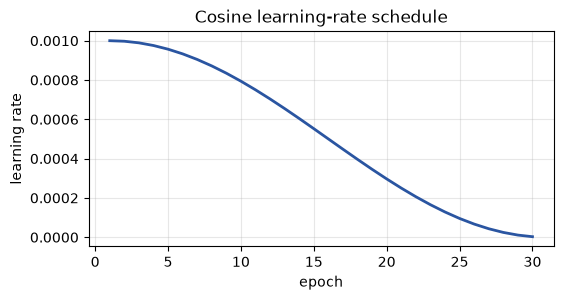

epoch 1: 0.001 | epoch 15: 0.000552 | epoch 30: 2.7e-06


In [19]:
# Simulate the schedule on a throw-away copy, so nothing real is changed.
tmp_opt = build_optimizer(cfg, copy.deepcopy(model))
tmp_sched = build_scheduler(cfg, tmp_opt)
lrs = []
for epoch in range(cfg.epochs):
    lrs.append(tmp_opt.param_groups[0]["lr"])   # learning rate used during this epoch
    tmp_opt.step()                              # (no gradients here, so no weight changes)
    tmp_sched.step()                            # end of epoch -> next learning rate

plt.figure(figsize=(6, 2.8))
plt.plot(range(1, cfg.epochs + 1), lrs, color=EXIT_COLORS[0], lw=2)
plt.xlabel("epoch"); plt.ylabel("learning rate"); plt.title("Cosine learning-rate schedule")
plt.grid(alpha=0.3); plt.show()
print("epoch 1:", lrs[0], "| epoch 15:", round(lrs[14], 6), "| epoch 30:", round(lrs[-1], 7))

## 8. Training

The training loop, in classroom terms:

```
for epoch in 1..30:
    model.train()                                 # dropout ON, BatchNorm uses batch statistics
    for each mini-batch (x, y) of 128 images:
        1. optimizer.zero_grad()                  # clear old gradients
        2. outputs = model(x)                     # FORWARD PASS -> 3 outputs (one per exit)
        3. loss = w1·L1 + w2·L2 + w3·L3           # LOSS
        4. loss.backward()                        # BACKPROPAGATION -> gradient of every weight
        5. optimizer.step()                       # WEIGHT UPDATE (Adam)
    validation on 5,000 images (no gradients)     # how well does it generalise?
    scheduler.step()                              # next learning rate
    save last.pt; save best.pt if Exit-3 validation accuracy improved
```

### 8.1 One training step in slow motion

Below, the five steps run once on one real batch, printing what happens at each step. It uses a **copy** of the
model, so nothing else changes and no file is written.

In [20]:
demo_model = copy.deepcopy(model).train()        # training mode: dropout ON, BatchNorm uses batch statistics
demo_opt = build_optimizer(cfg, demo_model)      # Adam, lr = 0.001
x, y = xb.to(DEVICE), yb.to(DEVICE)

demo_opt.zero_grad(set_to_none=True)             # STEP 1: clear old gradients
torch.manual_seed(123)                           # (fixes the dropout pattern so we can compare later)
logits = demo_model(x)                           # STEP 2: forward pass -> list of 3 tensors (128, 10)
loss, per_exit = loss_fn(logits, y)              # STEP 3: weighted multi-exit loss
print("STEP 3  loss before the update:", round(loss.item(), 4),
      "| per exit:", [round(l.item(), 4) for l in per_exit])

loss.backward()                                  # STEP 4: backpropagation (chain rule) fills p.grad
def grad_size(module):
    return torch.sqrt(sum((p.grad ** 2).sum() for p in module.parameters())).item()
print("STEP 4  gradient size per block (every block received a gradient):")
for i, s in enumerate(demo_model.stages):
    print(f"          Stage {i + 1}     : {grad_size(s):.4f}")
for i, h in enumerate(demo_model.heads):
    print(f"          Exit {i + 1} head : {grad_size(h):.4f}")

first_conv = demo_model.stages[0][0][0]          # Stage 1 -> first Conv-BN-ReLU block -> Conv2d layer
w_before = first_conv.weight.detach().clone()
demo_opt.step()                                  # STEP 5: Adam updates every weight using its gradient
print(f"STEP 5  average change of a first-layer weight: {(first_conv.weight - w_before).abs().mean().item():.6f}")

with torch.no_grad():                            # same batch, same dropout pattern, new weights
    torch.manual_seed(123)
    new_loss, _ = loss_fn(demo_model(x), y)
print("Result  loss on the same batch after ONE update:", round(new_loss.item(), 4),
      "(lower = the update moved the weights in a useful direction)")

STEP 3  loss before the update: 6.9346 | per exit: [2.3241, 2.2923, 2.3182]
STEP 4  gradient size per block (every block received a gradient):
          Stage 1     : 0.9611
          Stage 2     : 0.8303
          Stage 3     : 0.7405
          Exit 1 head : 0.7474
          Exit 2 head : 0.9767
          Exit 3 head : 1.4404
STEP 5  average change of a first-layer weight: 0.001000
Result  loss on the same batch after ONE update: 6.3725 (lower = the update moved the weights in a useful direction)


**Reading the result.** Every block received a gradient, so all three exits and all three stages learn. The
first-layer weights moved by about 0.001: on its very first step Adam moves each weight by roughly the learning
rate (0.001), in the direction that reduces the loss. The loss on the same batch dropped after one update.

### 8.2 The real training function

`train_one_epoch()` in `train.py` performs exactly these five steps for every mini-batch of an epoch. It also
moves each batch to the GPU and adds up the loss and the accuracy of each exit. (`scaler`/`amp` is optional mixed
precision, which was **off** for the reported runs.)

In [21]:
show_source(train_one_epoch)

def train_one_epoch(
    model: ThinkOrStopCNN,
    loader: DataLoader,
    loss_fn: MultiExitLoss,
    opt: torch.optim.Optimizer,
    device: torch.device,
    scaler: torch.amp.GradScaler | None = None,
    amp: bool = False,
    max_batches: int = 0,
) -> dict[str, float]:
    """One pass of forward propagation, weighted loss, backpropagation and update."""
    model.train()
    n_exits = model.num_exits
    total_loss, seen = 0.0, 0
    exit_loss = torch.zeros(n_exits, device=device)
    exit_correct = torch.zeros(n_exits, device=device)
    for b, (x, y) in enumerate(loader):
        if max_batches and b >= max_batches:
            break
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with _autocast(device, amp):
            logits = model(x)
        loss, per_exit = loss_fn(logits, y)
        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        else:
            loss.backward()
            opt.step()
        bs = y.size(0)
        seen += bs
        total_loss += loss.detach() * bs
        exit_loss += torch.stack(per_exit) * bs
        exit_correct += torch.stack([(z.argmax(1) == y).sum() for z in logits]).float()
    if seen == 0:
        raise RuntimeError("training loader yielded no batches")
    return _epoch_stats("train", float(total_loss) / seen, (exit_loss / seen).tolist(), (exit_correct / seen).tolist())

### 8.3 Validation

After every epoch the model is checked on the 5,000 validation images. `model.eval()` switches dropout **off**
and makes BatchNorm use its stored running statistics. `torch.inference_mode()` means **no gradients and no
weight updates**: we only measure how well the model **generalises** to images it did not train on.

In [22]:
show_source(validate)

@torch.inference_mode()
def validate(
    model: ThinkOrStopCNN, loader: DataLoader, loss_fn: MultiExitLoss, device: torch.device
) -> dict[str, float]:
    """Loss and accuracy of every exit on a held-out loader (no gradients)."""
    model.eval()
    n_exits = model.num_exits
    total_loss, seen = 0.0, 0
    exit_loss = torch.zeros(n_exits, device=device)
    exit_correct = torch.zeros(n_exits, device=device)
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        logits = model(x)
        loss, per_exit = loss_fn(logits, y)
        bs = y.size(0)
        seen += bs
        total_loss += float(loss) * bs
        exit_loss += torch.stack(per_exit) * bs
        exit_correct += torch.stack([(z.argmax(1) == y).sum() for z in logits]).float()
    return _epoch_stats("val", total_loss / seen, (exit_loss / seen).tolist(), (exit_correct / seen).tolist())

### 8.4 Checkpoint saving

After each epoch `run()` saves **`last.pt`** (latest state, used to resume an interrupted run). It also saves
**`best.pt`** whenever the **Exit-3 validation accuracy** improves. The baseline uses the same rule, so neither
model gains an advantage. A checkpoint stores the weights, the optimizer and scheduler state, the epoch, the
training history and the full configuration.

The cell below only **reads** the existing checkpoint of the reported run:

In [23]:
ckpt_path = ROOT / "checkpoints/cifar10_multiexit_s0/best.pt"
if ckpt_path.exists():
    ckpt = load_checkpoint(ckpt_path)            # read-only: loaded into memory, never written
    print("Stored items :", ", ".join(ckpt.keys()))
    print("Best epoch   :", ckpt["epoch"], "of", ckpt["config"]["epochs"])
    print("Best Exit-3 validation accuracy:", round(ckpt["best_score"], 4))
    print("Weight tensors stored:", len(ckpt["model_state"]))
else:
    print("No trained checkpoint found at", ckpt_path)

Stored items : config, model_state, optimizer_state, scheduler_state, scaler_state, epoch, best_score, select_metric, history, rng, exit_costs
Best epoch   : 29 of 30
Best Exit-3 validation accuracy: 0.9094
Weight tensors stored: 48


### 8.5 Full training (runs only when you ask for it)

`run()` is the same function used by `python -m think_or_stop.train`. It does everything above for 30 epochs:
it loads data, builds the model, loss, optimizer and scheduler, runs the training loop, validates, and saves
checkpoints and logs.

* Set `RUN_FULL_TRAINING = True` and run the cell. It takes about **3–6 minutes** on the RTX 5060 GPU.
* It writes to a **separate** run folder, `notebook_cifar10_multiexit_s0`, so the reported checkpoints are never
  overwritten. If that folder already has a trained model, the cell refuses to train again.

In [24]:
RUN_FULL_TRAINING = False          # <- change to True to really train the model

train_cfg = copy.deepcopy(cfg)
train_cfg.run_name = "notebook_cifar10_multiexit_s0"     # separate folder from the reported runs

if not RUN_FULL_TRAINING:
    print("Full training skipped (RUN_FULL_TRAINING = False).")
    print("Equivalent terminal command:")
    print("  python -m think_or_stop.train --dataset cifar10 --model multiexit --device cuda "
          "--epochs 30 --batch-size 128 --run-name notebook_cifar10_multiexit_s0")
elif (train_cfg.checkpoint_dir / "best.pt").exists():
    print("A notebook-trained model already exists in", train_cfg.checkpoint_dir,
          "- change train_cfg.run_name to train another one.")
else:
    summary = run(train_cfg)       # prints one line per epoch: loss, per-exit validation accuracy, time
    print(summary)

Full training skipped (RUN_FULL_TRAINING = False).
Equivalent terminal command:
  python -m think_or_stop.train --dataset cifar10 --model multiexit --device cuda --epochs 30 --batch-size 128 --run-name notebook_cifar10_multiexit_s0


### 8.6 Training curves of the reported run

These curves are **read from the saved log** of the real 30-epoch run (`results/logs/cifar10_multiexit_s0/history.csv`),
not recomputed here.

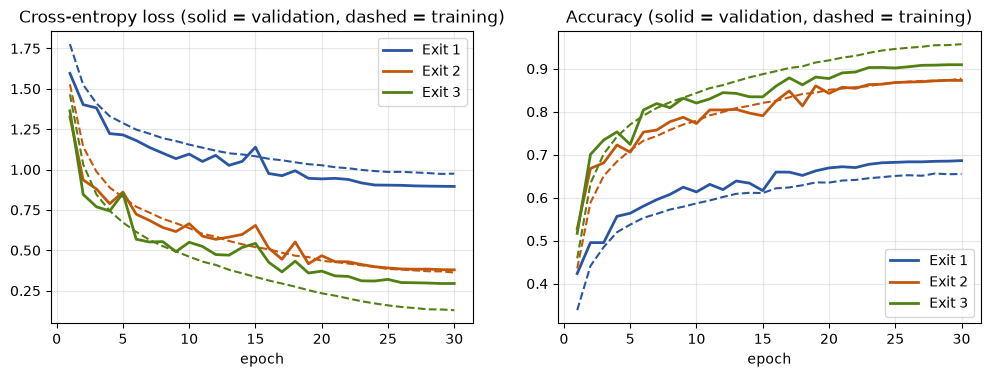

Final validation accuracy  Exit 1: 68.62%  Exit 2: 87.28%  Exit 3: 90.94%


In [25]:
hist_path = ROOT / "results/logs/cifar10_multiexit_s0/history.csv"
with open(hist_path) as fh:
    hist = list(csv.DictReader(fh))
ep = [int(r["epoch"]) for r in hist]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
for e in (1, 2, 3):
    c = EXIT_COLORS[e - 1]
    ax1.plot(ep, [float(r[f"train_loss_exit{e}"]) for r in hist], "--", color=c, lw=1.5)
    ax1.plot(ep, [float(r[f"val_loss_exit{e}"]) for r in hist], color=c, lw=2, label=f"Exit {e}")
    ax2.plot(ep, [float(r[f"train_acc_exit{e}"]) for r in hist], "--", color=c, lw=1.5)
    ax2.plot(ep, [float(r[f"val_acc_exit{e}"]) for r in hist], color=c, lw=2, label=f"Exit {e}")
ax1.set_title("Cross-entropy loss (solid = validation, dashed = training)")
ax2.set_title("Accuracy (solid = validation, dashed = training)")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.show()
last = hist[-1]
print("Final validation accuracy  Exit 1: {:.2%}  Exit 2: {:.2%}  Exit 3: {:.2%}".format(
    *(float(last[f"val_acc_exit{e}"]) for e in (1, 2, 3))))

## 9. Evaluation: testing the trained model

We load the trained model `checkpoints/cifar10_multiexit_s0/best.pt` (read-only) and test it on the **10,000 test
images** that were never used for training or tuning.

1. **Fixed exits:** the accuracy of each exit when every image uses that exit.
2. **Adaptive (Think-or-Stop) inference:** after Exit 1 and Exit 2, the image stops if the highest softmax
   probability (its **confidence**) is at least the threshold **τ**; otherwise it continues. τ was chosen earlier
   on the **validation** set by `evaluate.py` and is only read here.
3. **Sample predictions:** real test images with the predicted class, the confidence and the exit used.

*Note:* the accuracies are recomputed here on the GPU. They can differ from the saved evaluation by about one image
in 10,000 (0.01%), because GPU floating-point arithmetic can choose different calculation orders between runs.

In [26]:
EVAL_CKPT = ROOT / "checkpoints/cifar10_multiexit_s0/best.pt"
trained, trained_cfg, _ = load_model(EVAL_CKPT, DEVICE)   # rebuilds the architecture from the saved config,
                                                          # loads the weights and switches to eval() mode
test_loader = make_loader(splits.test, 256, shuffle=False, num_workers=0, device=DEVICE)

# Softmax probabilities of all 3 exits for all test images: shape (10000 images, 3 exits, 10 classes)
probs, targets = collect_probs(trained, test_loader, DEVICE)
print("Probability array:", probs.shape)

saved_exits = json.loads((ROOT / "results/metrics/cifar10_multiexit_s0/exits_test.json").read_text())
for e in range(3):
    acc = (probs[:, e].argmax(axis=1) == targets).mean()
    print(f"Exit {e + 1} test accuracy: {acc:.2%}   (saved evaluation result: {saved_exits[e]['accuracy']:.2%})")

Probability array: (10000, 3, 10)
Exit 1 test accuracy: 67.58%   (saved evaluation result: 67.59%)
Exit 2 test accuracy: 85.70%   (saved evaluation result: 85.70%)
Exit 3 test accuracy: 90.05%   (saved evaluation result: 90.04%)


In [27]:
# Adaptive inference with the threshold that evaluate.py selected on the VALIDATION set.
sel = json.loads((ROOT / "results/metrics/cifar10_multiexit_s0/threshold_selection.json").read_text())
tau = float(sel["selected_threshold"])
costs = compute_exit_costs(trained, (spec.in_channels, spec.image_size, spec.image_size))
summary = adaptive_summary(probs, targets, tau, costs, trained.exit_stages)

print(f"Threshold τ (chosen on validation data): {tau}")
print(f"Images stopping at Exit 1 / 2 / 3     : {summary['exit1_fraction']:.1%} / "
      f"{summary['exit2_fraction']:.1%} / {summary['exit3_fraction']:.1%}")
print(f"Adaptive test accuracy                : {summary['accuracy']:.2%}   "
      f"(always full network: {summary['full_depth_accuracy']:.2%})")
print(f"Average computation                   : {summary['relative_macs']:.1%} of the full network")

Threshold τ (chosen on validation data): 0.84
Images stopping at Exit 1 / 2 / 3     : 26.8% / 47.2% / 26.0%
Adaptive test accuracy                : 89.09%   (always full network: 90.05%)
Average computation                   : 62.6% of the full network


The numbers above are computed from the stored probabilities. The cell below runs the **real** early-exit code
`adaptive_predict()`, which actually skips the deeper stages for images that stop early, and checks that it gives
the same answers.

In [28]:
preds, exits = [], []
for xb_test, _ in test_loader:
    r = adaptive_predict(trained, xb_test.to(DEVICE), tau)   # stops each image at the first confident exit
    preds.append(r.predictions.cpu()); exits.append(r.exit_indices.cpu())
preds, exits = torch.cat(preds).numpy(), torch.cat(exits).numpy()

print(f"Real early-exit inference: accuracy {(preds == targets).mean():.2%}")
print("Images that stopped at Exit 1 / 2 / 3:", [int((exits == e).sum()) for e in range(3)])

Real early-exit inference: accuracy 89.09%
Images that stopped at Exit 1 / 2 / 3: [2684, 4717, 2599]


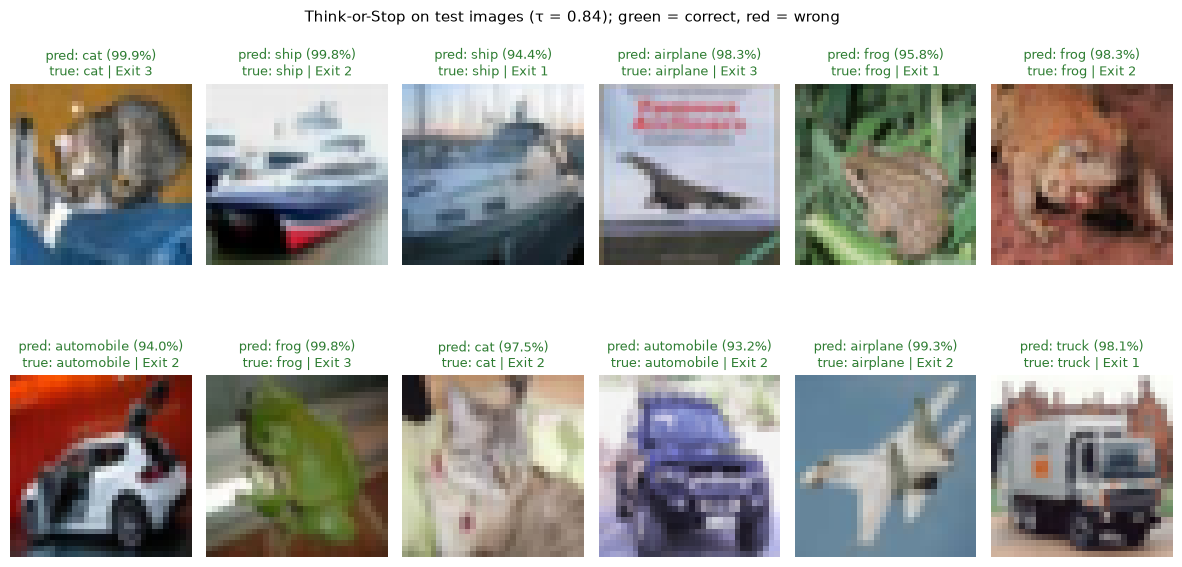

In [29]:
# Test the model on individual images: prediction, confidence and the exit that made the decision.
n = 12
images = torch.stack([splits.test[i][0] for i in range(n)])
labels = [splits.test[i][1] for i in range(n)]
r = adaptive_predict(trained, images.to(DEVICE), tau)

fig, axes = plt.subplots(2, 6, figsize=(15, 6.4))
for i, ax in enumerate(axes.flat):
    pred, conf, ex = int(r.predictions[i]), float(r.confidences[i]), int(r.exit_indices[i]) + 1
    ok = pred == labels[i]
    ax.imshow(to_image(images[i])); ax.axis("off")
    ax.set_title(f"pred: {spec.classes[pred]} ({conf:.1%})\ntrue: {spec.classes[labels[i]]} | Exit {ex}",
                 fontsize=9, color="#2E7D32" if ok else "#C62828")
plt.suptitle(f"Think-or-Stop on test images (τ = {tau}); green = correct, red = wrong", fontsize=11)
plt.subplots_adjust(hspace=0.45, wspace=0.08); plt.show()

**Optional: test your own picture.** Set `MY_IMAGE` to the path of a photo. It is resized to 32×32 and processed
exactly like a test image. The model only knows the 10 CIFAR-10 classes and was trained on tiny images, so
accuracy on everyday photos will be lower than on the test set.

Prediction: frog | confidence 99.9% | decided at Exit 2


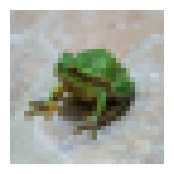

In [33]:
MY_IMAGE = r"C:\Users\asusm\OneDrive\Pictures\Screenshots\Screenshot 2026-10-27 133659.png"      # e.g. r"C:\Users\you\Pictures\cat.jpg"

if MY_IMAGE:
    img = Image.open(MY_IMAGE).convert("RGB").resize((spec.image_size, spec.image_size))
    r = adaptive_predict(trained, eval_tf(img).unsqueeze(0).to(DEVICE), tau)
    print(f"Prediction: {spec.classes[int(r.predictions[0])]} | confidence {float(r.confidences[0]):.1%} "
          f"| decided at Exit {int(r.exit_indices[0]) + 1}")
    plt.figure(figsize=(2, 2)); plt.imshow(img); plt.axis("off"); plt.show()
else:
    print("Set MY_IMAGE to an image path to try your own picture.")

## Summary

| Step | What happens | Where in the code |
|---|---|---|
| Dataset | 45,000 train / 5,000 validation (seed 42) / 10,000 test | `datasets.build_splits` |
| Preprocessing | ToTensor, Normalize; random crop + flip for training only; mini-batches of 128 | `datasets.build_transforms`, `make_loader` |
| Architecture | 3 stages (64→128→256 channels) with an exit classifier after each | `models.ThinkOrStopCNN` |
| Loss | `L = 1·L1 + 1·L2 + 1·L3` (cross-entropy per exit) | `losses.MultiExitLoss` |
| Optimizer | Adam, lr 0.001, weight decay 1e-4, cosine schedule | `train.build_optimizer`, `build_scheduler` |
| Training | zero_grad → forward → loss → backward → step, 30 epochs | `train.train_one_epoch`, `run` |
| Validation / checkpoint | Exit-3 validation accuracy decides `best.pt` | `train.validate`, `run` |
| Testing | per-exit accuracy; adaptive inference with τ chosen on validation | `evaluate`, `inference.adaptive_predict` |

The remaining experiments (GPU latency, noisy/blurred images, calibration, multi-seed tables and figures) are run
by `python -m think_or_stop.evaluate`, `plots` and `report`, as described in the project README and report.

In [6]:
from think_or_stop.models import ThinkOrStopCNN

model = ThinkOrStopCNN(in_channels=3)
print(model)

model.summary()

ThinkOrStopCNN(
  (stages): ModuleList(
    (0): Sequential(
      (0): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(128, 128

AttributeError: 'ThinkOrStopCNN' object has no attribute 'summary'